Generation: 0 Fitness: 0.02602
Generation: 10 Fitness: 0.05005
Generation: 20 Fitness: 0.05596
Generation: 30 Fitness: 0.05697
Generation: 40 Fitness: 0.05841
Generation: 50 Fitness: 0.05914
Generation: 60 Fitness: 0.06097
Generation: 70 Fitness: 0.06138
Generation: 80 Fitness: 0.06159
Generation: 90 Fitness: 0.06165

Optimized Robot Path:
(0, 0)
(0.24, 0.37)
(1.56, 2.49)
(6.41, 7.08)
(8.06, 8.63)
(8.58, 9.02)
(10, 10)

Path Length: 14.25
Smoothness: 0.44
Obstacle Penalty: 0


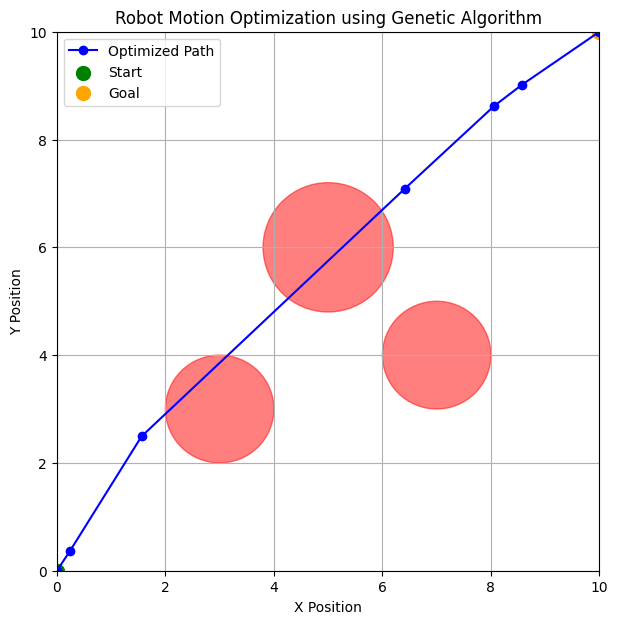

In [1]:


import random
import math
import matplotlib.pyplot as plt

# -------------------- Environment --------------------

START = (0, 0)
GOAL = (10, 10)

# Circular obstacles: (x, y, radius)
obstacles = [
    (3, 3, 1),
    (5, 6, 1.2),
    (7, 4, 1)
]

NUM_WAYPOINTS = 5
POPULATION_SIZE = 50
GENERATIONS = 100
MUTATION_RATE = 0.2

# -------------------- Helper Functions --------------------

def distance(p1, p2):
    return math.sqrt((p1[0] - p2[0])**2 +
                     (p1[1] - p2[1])**2)


def path_length(path):
    total = 0
    for i in range(len(path) - 1):
        total += distance(path[i], path[i + 1])
    return total


def smoothness(path):
    total = 0

    for i in range(1, len(path) - 1):
        a = path[i - 1]
        b = path[i]
        c = path[i + 1]

        v1 = (b[0] - a[0], b[1] - a[1])
        v2 = (c[0] - b[0], c[1] - b[1])

        dot = v1[0] * v2[0] + v1[1] * v2[1]
        mag1 = math.sqrt(v1[0]**2 + v1[1]**2)
        mag2 = math.sqrt(v2[0]**2 + v2[1]**2)

        if mag1 > 0 and mag2 > 0:
            cosine = max(-1, min(1, dot / (mag1 * mag2)))
            angle = math.acos(cosine)
            total += angle

    return total


def obstacle_penalty(path):
    penalty = 0

    for point in path:
        for ox, oy, radius in obstacles:
            d = distance(point, (ox, oy))

            if d < radius:
                penalty += 1000       # Collision penalty
            elif d < radius + 0.5:
                penalty += (radius + 0.5 - d) * 20

    return penalty


# -------------------- Genetic Algorithm --------------------

def create_individual():
    # Each individual contains intermediate points only
    return [
        (random.uniform(0, 10), random.uniform(0, 10))
        for _ in range(NUM_WAYPOINTS)
    ]


def get_path(individual):
    return [START] + individual + [GOAL]


def fitness(individual):
    path = get_path(individual)

    length = path_length(path)
    smooth = smoothness(path)
    obstacle = obstacle_penalty(path)

    # Minimize all three objectives
    cost = length + (2 * smooth) + obstacle

    return 1 / (1 + cost)


def selection(population):
    # Tournament selection
    candidates = random.sample(population, 3)
    return max(candidates, key=fitness)


def crossover(parent1, parent2):
    point = random.randint(1, NUM_WAYPOINTS - 1)

    child = parent1[:point] + parent2[point:]
    return child


def mutation(individual):
    for i in range(NUM_WAYPOINTS):
        if random.random() < MUTATION_RATE:
            x, y = individual[i]

            x += random.uniform(-1, 1)
            y += random.uniform(-1, 1)

            # Keep points inside the environment
            x = max(0, min(10, x))
            y = max(0, min(10, y))

            individual[i] = (x, y)

    return individual


# -------------------- Main Algorithm --------------------

population = [create_individual()
              for _ in range(POPULATION_SIZE)]

best_solution = None

for generation in range(GENERATIONS):

    new_population = []

    # Elitism: keep the best solution
    best = max(population, key=fitness)
    new_population.append(best)

    while len(new_population) < POPULATION_SIZE:
        parent1 = selection(population)
        parent2 = selection(population)

        child = crossover(parent1, parent2)
        child = mutation(child)

        new_population.append(child)

    population = new_population

    current_best = max(population, key=fitness)

    if best_solution is None or fitness(current_best) > fitness(best_solution):
        best_solution = current_best

    if generation % 10 == 0:
        print("Generation:", generation,
              "Fitness:", round(fitness(best_solution), 5))


# -------------------- Display Result --------------------

best_path = get_path(best_solution)

print("\nOptimized Robot Path:")
for point in best_path:
    print(tuple(round(value, 2) for value in point))

print("\nPath Length:", round(path_length(best_path), 2))
print("Smoothness:", round(smoothness(best_path), 2))
print("Obstacle Penalty:", round(obstacle_penalty(best_path), 2))


# -------------------- Plot the Path --------------------

plt.figure(figsize=(7, 7))

# Draw obstacles
for ox, oy, radius in obstacles:
    circle = plt.Circle((ox, oy), radius, color="red", alpha=0.5)
    plt.gca().add_patch(circle)

# Draw optimized path
x_values = [p[0] for p in best_path]
y_values = [p[1] for p in best_path]

plt.plot(x_values, y_values, "b-o", label="Optimized Path")

plt.scatter(*START, color="green", s=100, label="Start")
plt.scatter(*GOAL, color="orange", s=100, label="Goal")

plt.xlim(0, 10)
plt.ylim(0, 10)
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.title("Robot Motion Optimization using Genetic Algorithm")
plt.grid(True)
plt.legend()
plt.show()

#VARALAKSHMI SR [1BM25CS537]